#### Tarrataca’s Quantum Production System for the 3-Puzzle Problem

In [39]:
# Install the libraries
%pip install qiskit qiskit-aer numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
# Import the necessary libraries
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import UnitaryGate
from qiskit_aer import AerSimulator

In [41]:
# Define the 3 puzzle problem as a unitary matrix
# 0->blank
# 1,2,3->numbered tiles

initial_state = (1,0,3,2)
goal_state = (1,2,3,0)

def display_board(state):
    print(f"{state[0]} {state[1]}")
    print(f"{state[2]} {state[3]}")
    print()

print("Initial State:")
display_board(inital_state)

print("Goal State:")
display_board(goal_state)

Initial State:
1 0
3 2

Goal State:
1 2
3 0



In [42]:
def apply_rule(state, move):
    state = list(state)

    # Positions around the board in clockwise order
    cycle = [0, 1, 3, 2]

    blank_position = state.index(0)
    cycle_position = cycle.index(blank_position)

    if move == 1:
        # Clockwise
        next_position = cycle[(cycle_position + 1) % 4]
    else:
        # Counterclockwise
        next_position = cycle[(cycle_position - 1) % 4]

    state[blank_position], state[next_position] = (
        state[next_position],
        state[blank_position]
    )

    return tuple(state)


print("Counterclockwise result:")
display_board(apply_rule(initial_state, 0))

print("Clockwise result:")
display_board(apply_rule(initial_state, 1))

Counterclockwise result:
0 1
3 2

Clockwise result:
1 2
3 0



In [43]:
# Encode the board into binary
def encode_board(state):
    value = 0
    for position, tile in enumerate(state):
        value |= (tile<<(2*position))

    return value


def decode_board(value):
    return tuple(
        (value>>(2*position))&3
        for position in range(4)
    )


initial_code = encode_board(initial_state)
goal_code = encode_board(goal_state)

print("initial binary encoding:",format(initial_code,'08b'))
print("goal binary encoding:",format(goal_code,'08b'))
print("Decoded initial state:",decode_board(initial_code))


initial binary encoding: 10110001
goal binary encoding: 00111001
Decoded initial state: (1, 0, 3, 2)


In [44]:
# Construct the reversible production operator

BOARD_DIM = 256
MOVE_DIM = 4
TOTAL_DIM = BOARD_DIM * MOVE_DIM


def next_board_code(board_code, move):
    state = decode_board(board_code)

    # Check whether the board contains all three tiles and the blank
    if sorted(state) != [0, 1, 2, 3]:
        return board_code

    return encode_board(apply_rule(state, move))


move_matrix = np.zeros((TOTAL_DIM, TOTAL_DIM), dtype=complex)

for move_code in range(MOVE_DIM):
    for board_code in range(BOARD_DIM):

        if move_code in (0, 1):
            new_board = next_board_code(board_code, move_code)
        else:
            new_board = board_code

        input_index = board_code + move_code * BOARD_DIM
        output_index = new_board + move_code * BOARD_DIM

        move_matrix[output_index, input_index] = 1


production_gate = UnitaryGate(
    move_matrix,
    label="Reversible Rules"
)

print("Production gate qubits:", production_gate.num_qubits)
print("Expected: 10")

Production gate qubits: 10
Expected: 10


In [45]:
# Create the target state oracle
oracle_matrix = np.eye(TOTAL_DIM, dtype=complex)

for move_code in range(MOVE_DIM):
    input_index = goal_code + move_code * BOARD_DIM
    oracle_matrix[input_index, input_index] = -1

oracle_gate = UnitaryGate(
    oracle_matrix,
    label="Goal Oracle"
)

print("Goal oracle created.")

Goal oracle created.


In [46]:
# Build the quantum production system 
def build_circuit(use_grover=True):
    board = QuantumRegister(8, name="board")
    move = QuantumRegister(2, name="move")
    output = ClassicalRegister(10, name="output")

    qc = QuantumCircuit(board, move, output)

    for position,tile in enumerate(initial_state):
        for bit in range(2):
            if (tile>>bit)&1:
                qc.x(board[2*position+bit])


    qc.h(move[0])
    qc.h(move[1])

    all_qubits = list(board) + list(move)

    qc.append(production_gate, all_qubits)

    if use_grover:
        qc.append(oracle_gate, all_qubits)
        qc.append(production_gate.inverse(),all_qubits)

        qc.h(move)
        qc.x(move)
        qc.cz(move[0], move[1])
        qc.x(move)
        qc.h(move)

        qc.append(production_gate, all_qubits)

    qc.measure(board, output[0:8])
    qc.measure(move, output[8:10])

    return qc


qc = build_circuit(use_grover=True)
print(qc.draw(output="text",fold=120))

           ┌───┐┌───────────────────┐┌──────────────┐┌──────────┐                       ┌───────────────────┐┌─┐      »
  board_0: ┤ X ├┤0                  ├┤0             ├┤0         ├───────────────────────┤0                  ├┤M├──────»
           └───┘│                   ││              ││          │                       │                   │└╥┘┌─┐   »
  board_1: ─────┤1                  ├┤1             ├┤1         ├───────────────────────┤1                  ├─╫─┤M├───»
                │                   ││              ││          │                       │                   │ ║ └╥┘┌─┐»
  board_2: ─────┤2                  ├┤2             ├┤2         ├───────────────────────┤2                  ├─╫──╫─┤M├»
                │                   ││              ││          │                       │                   │ ║  ║ └╥┘»
  board_3: ─────┤3                  ├┤3             ├┤3         ├───────────────────────┤3                  ├─╫──╫──╫─»
           ┌───┐│                   ││  

In [47]:
# Execute the circuit
simulator = AerSimulator()

job = simulator.run(qc, shots=1024)
counts = job.result().get_counts()

print("Measurement Results:")
print(counts)

Measurement Results:
{'0100111001': 1024}


In [48]:
goal_shots = 0
move_counts = [0, 0, 0, 0]

for bitstring, count in counts.items():
    board_code = int(bitstring[-8:], 2)
    move_code = int(bitstring[:2], 2)

    move_counts[move_code] += count

    print(
        f"Move choice: {move_code:02b}, "
        f"Board: {decode_board(board_code)}, "
        f"Count: {count}"
    )

    if board_code == goal_code:
        goal_shots += count

success_rate = goal_shots / sum(counts.values()) * 100

print("\nGoal state:", goal_state)
print("Successful shots:", goal_shots)
print(f"Goal-state success rate: {success_rate:.2f}%")

Move choice: 01, Board: (1, 2, 3, 0), Count: 1024

Goal state: (1, 2, 3, 0)
Successful shots: 1024
Goal-state success rate: 100.00%


Without Grover amplification: 28.03%
With Grover amplification:    100.00%


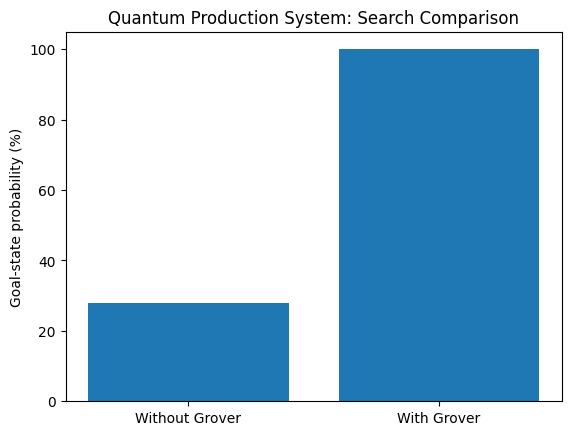

In [49]:
baseline_circuit = build_circuit(use_grover=False)

baseline_counts = simulator.run(
    baseline_circuit,
    shots=1024
).result().get_counts()


def calculate_goal_rate(counts):
    successful = sum(
        count
        for bitstring, count in counts.items()
        if int(bitstring[-8:], 2) == goal_code
    )

    total = sum(counts.values())
    return 100 * successful / total


baseline_rate = calculate_goal_rate(baseline_counts)

print(f"Without Grover amplification: {baseline_rate:.2f}%")
print(f"With Grover amplification:    {success_rate:.2f}%")

plt.bar(
    ["Without Grover", "With Grover"],
    [baseline_rate, success_rate]
)

plt.ylabel("Goal-state probability (%)")
plt.title("Quantum Production System: Search Comparison")
plt.ylim(0, 105)
plt.show()